# Bài toán 3 — Phân tích sai số và độ nhạy

## 8. Phân tích lỗi và độ nhạy

### 8.1. Sai số từng ngày

Biểu đồ đối chiếu dự báo với thực tế trên tập test. Sai số có dấu bằng dự báo trừ thực tế. Giá trị âm là dự báo thấp hơn thực tế, giá trị dương là dự báo cao hơn.

Dùng dự báo đã lưu từ notebook 02 để đối chiếu với thực tế.

In [1]:
from pathlib import Path
import os

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

sales_path = Path("data/raw/sales.csv")
start = Path(os.environ.get("RETAIL_ANALYTICS_ROOT", Path.cwd())).resolve()
project_root = next(
    (folder for folder in (start, *start.parents) if (folder / sales_path).is_file()),
    None,
)
if project_root is None:
    raise FileNotFoundError(
        "Không tìm thấy data/raw/sales.csv. Hãy đặt notebook trong dự án "
        "hoặc trỏ RETAIL_ANALYTICS_ROOT về thư mục gốc."
    )

prediction_path = project_root / "data/model/du_bao/forecast_predictions.csv"
if not prediction_path.is_file():
    raise FileNotFoundError("Chạy 02_mo_hinh.ipynb để tạo forecast_predictions.csv.")

predictions = pd.read_csv(
    prediction_path, parse_dates=["Date", "TrainEnd"], float_precision="round_trip",
)
targets = ["Revenue", "COGS"]

observed = pd.read_csv(
    project_root / sales_path, usecols=["Date", *targets], parse_dates=["Date"],
).set_index("Date").sort_index()[targets]
if not observed.index.is_unique:
    raise ValueError("sales.csv có ngày trùng. Kiểm tra lại ở 01_du_lieu.ipynb.")

contest_name = "Baseline cuộc thi"
fixed_name = "Mùa vụ, mức gốc cố định"
selected_label = "Phương pháp được chọn"


def prediction_frame(rows):
    return rows.set_index("Date")[targets].sort_index()


def test_forecast_for(method):
    return prediction_frame(predictions.loc[
        predictions["Split"].eq("test") & predictions["Method"].eq(method)
    ])

from io import BytesIO
from IPython.display import Image

to_millions = 1_000_000


selected_test_forecast = test_forecast_for(selected_label)
final_dates = selected_test_forecast.index
test_actual = observed.loc[final_dates]

Revenue — 5 ngày lệch nhiều nhất (triệu đơn vị tiền tệ)
COGS — 5 ngày lệch nhiều nhất (triệu đơn vị tiền tệ)


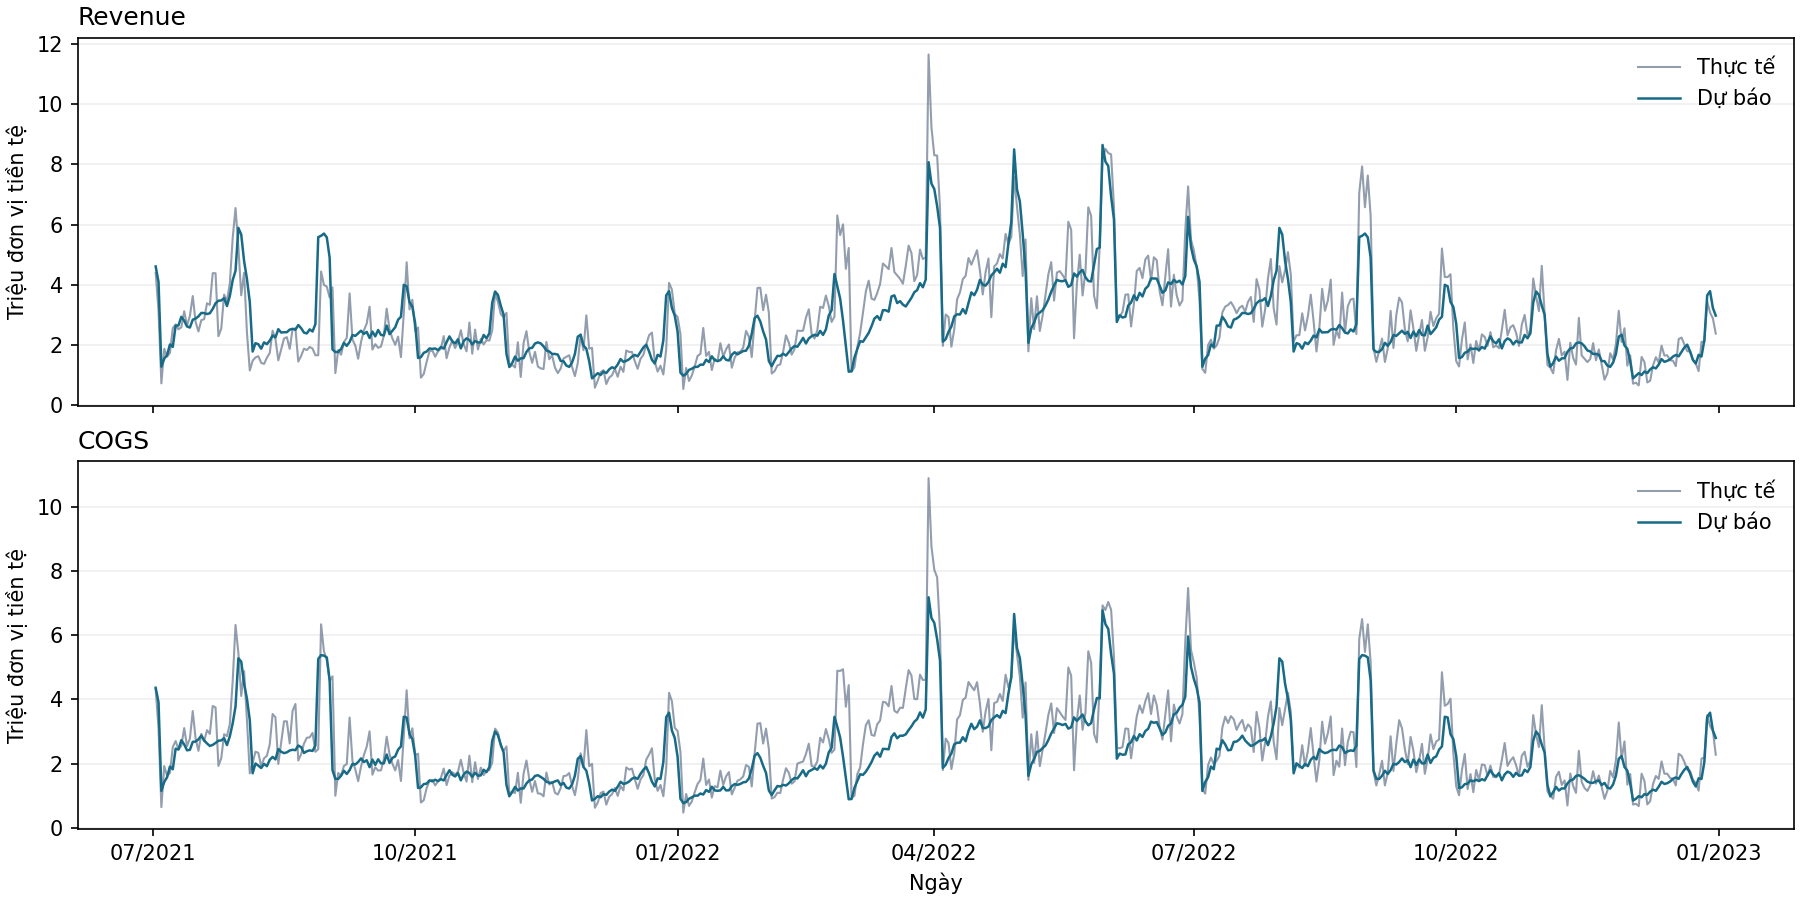

,Thực tế,Dự báo,Sai số có dấu,Sai số tuyệt đối
Date,,,,
2022-03-02,5.222,1.117,-4.105,4.105
2021-08-28,1.665,5.584,3.919,3.919
2022-03-30,11.643,8.070,-3.574,3.574
2022-02-28,6.007,2.817,-3.191,3.191
2022-03-01,4.533,1.953,-2.580,2.580


,Thực tế,Dự báo,Sai số có dấu,Sai số tuyệt đối
Date,,,,
2022-03-30,10.896,7.184,-3.712,3.712
2022-03-02,4.446,0.892,-3.555,3.555
2021-09-02,4.722,1.796,-2.926,2.926
2021-08-28,2.453,5.263,2.809,2.809
2022-02-28,4.943,2.221,-2.722,2.722


In [2]:
from matplotlib import dates as mdates

fig, axes = plt.subplots(2, 1, figsize=(12, 6), sharex=True, layout="constrained")
for ax, target in zip(axes, targets):
    ax.plot(final_dates, test_actual[target] / to_millions, label="Thực tế",
            color="#64748B", alpha=0.7, linewidth=1.0)
    ax.plot(final_dates, selected_test_forecast[target] / to_millions, label="Dự báo",
            color="#176B87", linewidth=1.2)
    ax.set_title(target, loc="left")
    ax.set_ylabel("Triệu đơn vị tiền tệ")
    ax.grid(axis="y", alpha=0.2)
    ax.legend(loc="upper right", frameon=False)
axes[-1].xaxis.set_major_locator(mdates.MonthLocator(interval=3))
axes[-1].xaxis.set_major_formatter(mdates.DateFormatter("%m/%Y"))
axes[-1].set_xlabel("Ngày")
with BytesIO() as buffer:
    fig.savefig(buffer, format="png", dpi=150)
    display(Image(data=buffer.getvalue(), width=950))
plt.close(fig)

daily_errors = {}
for target in targets:
    errors = pd.DataFrame({
        "Thực tế": test_actual[target],
        "Dự báo": selected_test_forecast[target],
    })
    errors["Sai số có dấu"] = errors["Dự báo"] - errors["Thực tế"]
    errors["Sai số tuyệt đối"] = errors["Sai số có dấu"].abs()
    daily_errors[target] = errors
    print(f"{target} — 5 ngày lệch nhiều nhất (triệu đơn vị tiền tệ)")
    display((errors.nlargest(5, "Sai số tuyệt đối") / to_millions).round(3))

### 8.2. Độ nhạy theo thành phần mô hình, kỳ dự báo và cửa sổ trung bình

So sánh có và bỏ hệ số tăng trưởng trên từng lượt validation. Sau đó đo MAE tại bốn độ dài từ cùng một mốc dự báo. Mỗi độ dài sử dụng các ngày đầu của dự báo 548 ngày, giữ nguyên toàn bộ dữ liệu train.

Phép thử bổ sung thay cửa sổ của mốc trung bình thành 14, 28 và 56 ngày. Các kết quả này mô tả độ nhạy trên validation và được ghi riêng với kết quả test.

In [3]:
def evaluate(actual, forecast):
    pd.testing.assert_index_equal(actual.index, forecast.index)
    pd.testing.assert_index_equal(actual.columns, forecast.columns)
    if not np.isfinite(forecast.to_numpy(dtype=float)).all():
        raise ValueError("Dự báo có giá trị thiếu hoặc không hữu hạn.")
    actual = actual.astype(float) / 1_000_000
    error = forecast.astype(float) / 1_000_000 - actual
    squared_error = error.pow(2)
    variation = (actual - actual.mean()).pow(2).sum()
    return pd.DataFrame({
        "MAE": error.abs().mean(),
        "RMSE": np.sqrt(squared_error.mean()),
        "R²": 1 - squared_error.sum() / variation.where(variation > 0),
    }).rename_axis("Chỉ tiêu")


def repeat_level(level, dates):
    return pd.DataFrame(
        np.tile(level.to_numpy(dtype=float), (len(dates), 1)),
        index=dates, columns=level.index,
    )

validation_predictions = {}
validation_actual = {}
train_ends = {}
score_rows = []

validation = predictions.loc[predictions["Split"].eq("validation")]
for (fold_id, method), rows in validation.groupby(["Fold", "Method"], sort=False):
    forecast = prediction_frame(rows)
    actual = observed.loc[forecast.index]
    validation_predictions[fold_id, method] = forecast
    validation_actual[fold_id] = actual
    train_ends[fold_id] = rows["TrainEnd"].iloc[0]
    score_rows.append(evaluate(actual, forecast).assign(Fold=fold_id, Method=method))

validation_scores = pd.concat(score_rows).reset_index().rename(columns={"Method": "Phương pháp"})


comparison_methods = [contest_name, fixed_name]
by_fold = validation_scores.loc[validation_scores["Phương pháp"].isin(comparison_methods)]
display(by_fold.pivot(index="Fold", columns=["Phương pháp", "Chỉ tiêu"], values="MAE").round(3))

horizon_rows = []
for length in (28, 182, 365, 548):
    for fold_id, actual in validation_actual.items():
        for name in comparison_methods:
            forecast = validation_predictions[fold_id, name]
            score = evaluate(actual.iloc[:length], forecast.iloc[:length])
            horizon_rows.append(score.assign(Số_ngày=length, Phương_pháp=name))
horizon_scores = pd.concat(horizon_rows).reset_index()
display(
    horizon_scores.pivot_table(index="Số_ngày", columns=["Phương_pháp", "Chỉ tiêu"], values="MAE")
    .rename_axis(index="Số ngày dự báo", columns=["Phương pháp", "Chỉ tiêu"])
    .round(3)
)

window_rows = []
for width in (14, 28, 56):
    for fold_id, train_end in train_ends.items():
        train = observed.loc[:train_end, targets]
        actual = validation_actual[fold_id]
        score = evaluate(actual, repeat_level(train.tail(width).mean(), actual.index))
        window_rows.append(score.assign(Cửa_sổ=width, Fold=fold_id))
window_scores = pd.concat(window_rows).reset_index()
display(window_scores.pivot_table(index="Cửa_sổ", columns="Chỉ tiêu", values="MAE").round(3))

Phương pháp Baseline cuộc thi        Mùa vụ, mức gốc cố định       
Chỉ tiêu              Revenue   COGS                 Revenue   COGS
Fold                                                               
1                       1.454  1.216                   1.180  0.967
2                       2.070  1.876                   1.797  1.615
3                       0.601  0.493                   0.659  0.562

Phương pháp    Baseline cuộc thi         Mùa vụ, mức gốc cố định        
Chỉ tiêu                    COGS Revenue                    COGS Revenue
Số ngày dự báo                                                          
28                         0.601   0.676                   0.549   0.621
182                        0.939   1.053                   0.910   1.035
365                        1.099   1.274                   0.984   1.138
548                        1.195   1.375                   1.048   1.212

Chỉ tiêu,COGS,Revenue
Cửa_sổ,,
14,2.881,3.338
28,2.504,3.091
56,2.607,3.275


**Nhận xét độ nhạy.** Khi lấy trung bình qua ba lượt, phương pháp giữ mức gốc cố định có MAE thấp hơn baseline có tăng trưởng ở cả bốn độ dài đã xét. Kết quả từng lượt vẫn khác nhau. Với mốc trung bình, cửa sổ 28 ngày cho MAE thấp nhất trong ba cửa sổ thử ở cả Revenue và COGS.